## Load and prepare the data

In [2]:
import numpy as np
import pandas as pd

X_test = pd.read_csv("X_test.csv", index_col="target_month", parse_dates=True)
y_test = pd.read_csv("y_test.csv", index_col="target_month", parse_dates=True)
X_train = pd.read_csv("X_train.csv", index_col="target_month", parse_dates=True)
y_train = pd.read_csv("y_train.csv", index_col="target_month", parse_dates=True)

In [3]:
y_train = y_train[['pr_pc1']]
y_test = y_test[['pr_pc1']]

In [4]:
print("Mean of y_train:", round(y_train['pr_pc1'].mean(), 2))
print("Standart deviation of y_train:", round(y_train['pr_pc1'].std(), 2))
print("======================================")
print("Mean of y_test:", round(y_test['pr_pc1'].mean(), 2))
print("Standart deviation of y_test:", round(y_test['pr_pc1'].std(), 2))

Mean of y_train: -0.0
Standart deviation of y_train: 24.27
Mean of y_test: -7.47
Standart deviation of y_test: 21.19


In [5]:
from sklearn.preprocessing import StandardScaler

# Initialize and transform
scaler = StandardScaler()
X_train_st = scaler.fit_transform(X_train)
X_test_st = scaler.transform(X_test)

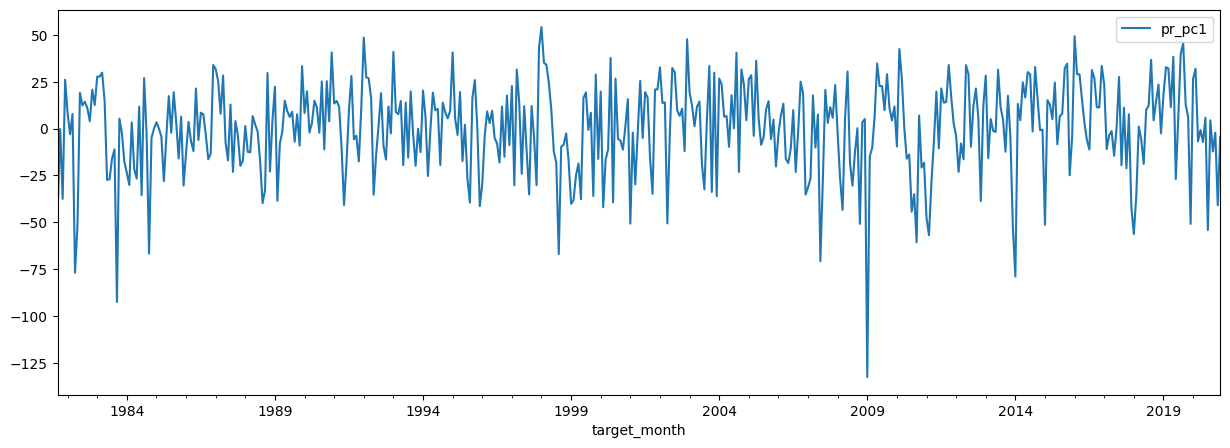

In [6]:
import matplotlib.pyplot as plt

y_train.plot(y='pr_pc1', kind='line', figsize=(15, 5))
plt.show()

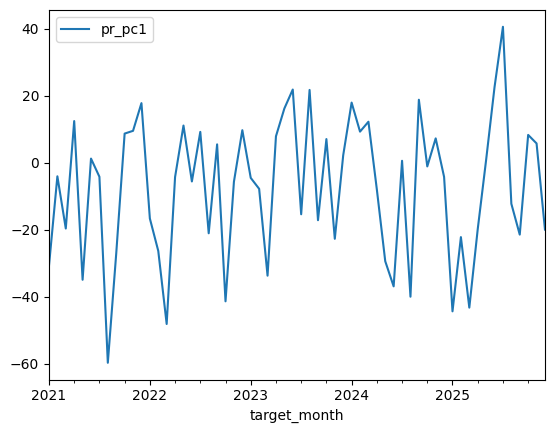

In [7]:
y_test.plot(y='pr_pc1', kind='line')
plt.show()

# Train models

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluation(title, pred, test):
  print("=======================")
  print(title)
  print("-----------------------")
  print(f"MAE: {round(mean_absolute_error(test, pred), 2)}")
  print(f"RMSE: {round(mean_squared_error(test, pred)**0.5, 2)}")
  print(f"R2: {round(r2_score(test, pred), 2)}")


#baseline
y_pred_baseline = np.zeros_like(y_test.to_numpy())




evaluation("Baseline", y_pred_baseline, y_test)

Baseline
-----------------------
MAE: 537.52
RMSE: 683.42
R2: -0.12


## Linear regression

In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


def make_model(regressor):
    pipeline = make_pipeline(
        StandardScaler(),
        regressor
    )
    return TransformedTargetRegressor(
        regressor=pipeline,
        transformer=StandardScaler()
    )


models = {
    "Linear Regression": {
        "model": make_model(LinearRegression()),
        "params": {}
    },

    "Lasso": {
        "model": make_model(Lasso(max_iter=50000)),
        "params": {
            "regressor__lasso__alpha": np.logspace(-3, 1, 9)
        }
    },

    "Ridge": {
        "model": make_model(Ridge()),
        "params": {
            "regressor__ridge__alpha": np.logspace(-3, 3, 13)
        }
    },

    "Elastic Net": {
        "model": make_model(ElasticNet(max_iter=50000)),
        "params": {
            "regressor__elasticnet__alpha": np.logspace(-3, 1, 9),
            "regressor__elasticnet__l1_ratio": [
                0.1, 0.25, 0.5, 0.75, 0.9
            ]
        }
    }
}

# Chronological cross-validation: never shuffle time series
tscv = TimeSeriesSplit(n_splits=5)

best_models = {}
cv_results = []

for model_name, config in models.items():
    search = GridSearchCV(
        estimator=config["model"],
        param_grid=config["params"],
        scoring="r2",
        cv=tscv,
        refit=True,
        n_jobs=-1
    )

    search.fit(X_train_st, y_train)

    best_models[model_name] = search.best_estimator_

    cv_results.append({
        "model": model_name,
        "CV_mean_R2": search.best_score_,
        "best_params": search.best_params_
    })

for model_name, model in best_models.items():
    y_pred = model.predict(X_test_st)
    evaluation(model_name, y_pred, y_test)

Linear Regression
-----------------------
MAE: 529.36
RMSE: 651.75
R2: -0.02
Lasso
-----------------------
MAE: 522.57
RMSE: 651.77
R2: -0.02
Ridge
-----------------------
MAE: 526.96
RMSE: 650.6
R2: -0.02
Elastic Net
-----------------------
MAE: 515.07
RMSE: 652.75
R2: -0.03


## Random forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [70, 100],
    "max_depth": [3, 10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, "sqrt"]
}

# Chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train_st, y_train)

best_rf = search.best_estimator_

evaluation("Random Forest", best_rf.predict(X_test_st), y_test)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Random Forest
-----------------------
MAE: 507.19
RMSE: 621.43
R2: 0.07


In [ ]:
best_rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': 20,
 'max_features': 0.7,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 4,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

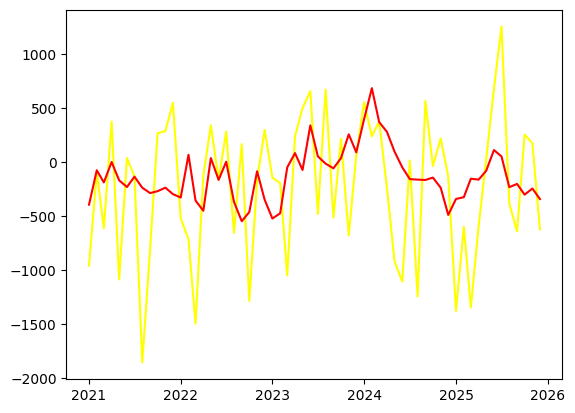

In [ ]:
plt.plot(y_test.index, y_test['pr_pc1'], color='yellow')
plt.plot(y_test.index, best_rf.predict(X_test_st), color='red')

plt.show()

## Gradient boosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

model = GradientBoostingRegressor(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 5, 7],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [1, 2, 3, 5, 10],
    'subsample': [0.8, 1.0],
}

# Chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    refit=True,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train_st, y_train)

best_gb = search.best_estimator_

evaluation("Gradient Boosting", best_gb.predict(X_test_st), y_test)

Fitting 5 folds for each of 960 candidates, totalling 4800 fits


/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


Gradient Boosting
-----------------------
MAE: 514.99
RMSE: 640.79
R2: 0.01


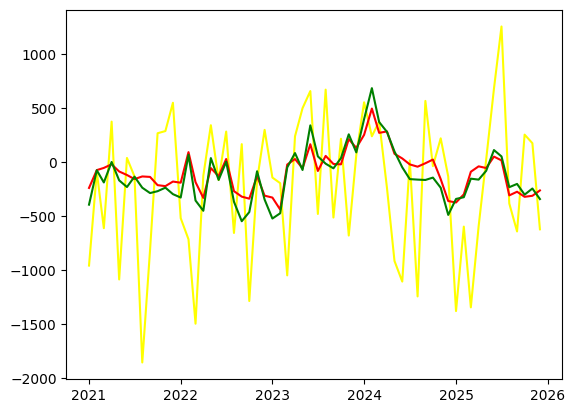

In [ ]:
plt.plot(y_test.index, y_test['pr_pc1'], color='yellow')
plt.plot(y_test.index, best_gb.predict(X_test_st), color='red')
plt.plot(y_test.index, best_rf.predict(X_test_st), color='green')

plt.show()

## Multi-layer perceptron

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. Prepare data
# ==========================================

# Convert to numpy arrays
X_train = np.asarray(X_train_st, dtype=np.float32)
X_test = np.asarray(X_test_st, dtype=np.float32)

y_train = np.asarray(y_train, dtype=np.float32).reshape(-1, 1)
y_test = np.asarray(y_test, dtype=np.float32).reshape(-1, 1)

# Check dimensions
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train)

X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test)


# ==========================================
# 2. Create DataLoader
# ==========================================

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False
)


# ==========================================
# 3. Define MLP architecture
# ==========================================

class MLP(nn.Module):

    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 32),
            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Initialize model
input_size = X_train.shape[1]

model = MLP(input_size)

print(model)


# ==========================================
# 4. Loss and optimizer
# ==========================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.001
)


# ==========================================
# 5. Training
# ==========================================

epochs = 300
patience = 30

best_loss = float("inf")
counter = 0

best_model_state = None

train_losses = []

for epoch in range(epochs):

    model.train()
    epoch_loss = 0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        optimizer.step()

        epoch_loss += loss.item() * len(X_batch)

    epoch_loss /= len(train_dataset)

    train_losses.append(epoch_loss)

    # Early stopping based on training loss
    if epoch_loss < best_loss:
        best_loss = epoch_loss
        counter = 0

        best_model_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }

    else:
        counter += 1

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {epoch_loss:.6f}"
        )

    if counter >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break


# Restore best model
model.load_state_dict(best_model_state)


# ==========================================
# 6. Predictions
# ==========================================

model.eval()

with torch.no_grad():

    y_pred = model(X_test_tensor).numpy().flatten()

y_true = y_test.flatten()


# ==========================================
# 7. Evaluation
# ==========================================

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

r2 = r2_score(y_true, y_pred)

correlation = np.corrcoef(y_true, y_pred)[0, 1]

print("\nMLP TEST RESULTS")
print("=" * 40)

print(f"MAE:         {mae:.4f}")
print(f"RMSE:        {rmse:.4f}")
print(f"R2:          {r2:.4f}")
print(f"Correlation: {correlation:.4f}")

X_train: (472, 8)
X_test: (60, 8)
y_train: (472, 1)
y_test: (60, 1)
MLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=1, bias=True)
  )
)
Epoch [25/300], Loss: 536892.324153
Epoch [50/300], Loss: 488245.328390
Epoch [75/300], Loss: 470858.716102
Epoch [100/300], Loss: 464030.284958
Epoch [125/300], Loss: 457481.991525
Epoch [150/300], Loss: 465130.950212
Epoch [175/300], Loss: 454552.283898
Epoch [200/300], Loss: 445567.530720
Epoch [225/300], Loss: 449534.718220
Epoch [250/300], Loss: 441011.584746
Epoch [275/300], Loss: 439313.596928
Early stopping at epoch 298

MLP TEST RESULTS
MAE:         543.1184
RMSE:        641.1692
R2:          0.0106
Correlation: 0.2416


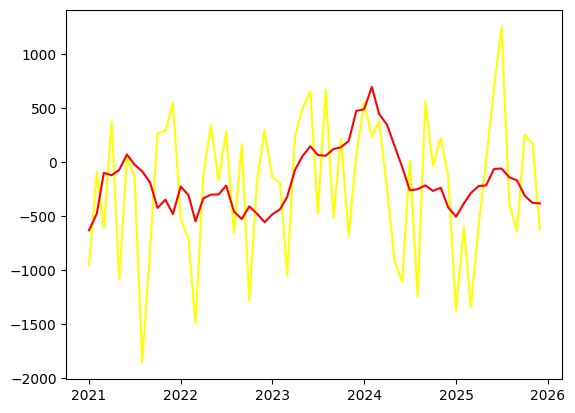

In [ ]:
plt.plot(y_test.index, y_test['pr_pc1'], color='yellow')
plt.plot(y_test.index, y_pred, color='red')

plt.show()

# Aligning predictions with the data

In [8]:
from sklearn.ensemble import RandomForestRegressor

rf_params = {'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': 20,
 'max_features': 0.7,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 4,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': -1,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

model = RandomForestRegressor(**rf_params)
model.fit(X_train_st, y_train)

y_pred = pd.DataFrame(model.predict(X_test_st), index=y_test.index, columns=["predictions"])

compare = y_test.join(y_pred)
compare.describe().loc[['mean', 'std', 'min', 'max']].round(2)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,pr_pc1,predictions
mean,-7.47,-4.05
std,21.19,8.05
min,-59.70,-19.48
max,40.55,22.66


In [29]:
print(round(compare['pr_pc1'].corr(compare['predictions']), 4))

0.3142


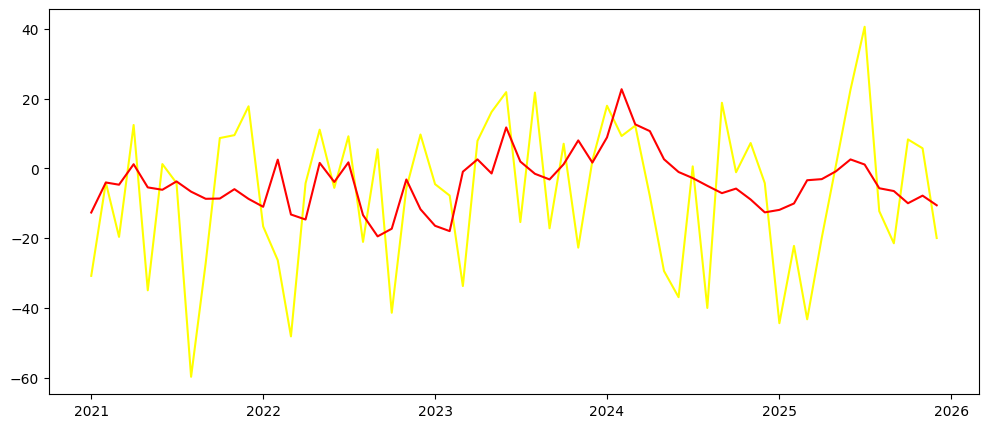

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))  # 10 inches wide, 6 inches tall
plt.plot(compare.index, compare['pr_pc1'], color='yellow')
plt.plot(compare.index, compare['predictions'], color='red')

plt.show()

# Exporting models

In [41]:
import joblib

# Save model
joblib.dump(model, "model.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']